<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>

<a href="https://query.farm/vgi/"><img src="assets/vgi-logo.png" alt="Vector Gateway Interface" width="170"></a>

# What gets lost when holdings weights are rounded?

A holding’s market value divided by its portfolio-weight fraction implies a denominator. If a displayed weight has been rounded, using it in that division can introduce error—especially for small positions. We will retrieve **DGRW** holdings through the real WisdomTree worker, inspect the denominator implied by the original values, then deliberately round weights in SQL and measure the effect.

The default replays **three official responses captured November 14, 2026**. The holdings are real; the rounding is an explicitly constructed experiment, **not a claim that WisdomTree supplied rounded weights**. This is a numerical data-quality exercise, not an official net-asset calculation, valuation opinion or investment recommendation. [Setup, provenance and limitations](README.md).

## Choose the display precision

`WEIGHT_DECIMALS` is the number of decimal places retained in **percentage-point weights**, an integer 0–4. At 2, the rounding increment is 0.01 percentage points, or 0.01% of reported assets. At 1, it is 0.1 percentage points. The original market values and weights are preserved in separate columns.

`DATA_MODE="recorded"` uses the fixed official recording; `"live"` fetches current DGRW holdings and updates dates and labels. This endpoint has no historical date argument. Edit, restart, and run all. The end experiment changes only the precision from 2 to 1.

In [1]:
WEIGHT_DECIMALS = 2  # decimal places in percentage-point weights; integer 0..4
DATA_MODE = "recorded"  # recorded or live

In [2]:
import haybarn
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from matplotlib.ticker import FuncFormatter, NullFormatter

from notebook_support import chart, cleanup, configure, prose, theme, verify_audit

previous, audit, run_at = configure(WEIGHT_DECIMALS, DATA_MODE)
theme()
precision_label = f"{WEIGHT_DECIMALS} decimal place" + ("" if WEIGHT_DECIMALS == 1 else "s")
connection = haybarn.connect()
%load_ext sql
%config SqlMagic.autopandas = True
%config SqlMagic.displaycon = False
%config SqlMagic.feedback = False
connection.execute("CREATE TABLE settings AS SELECT ?::INTEGER AS decimals", [WEIGHT_DECIMALS])
%sql connection

Tip: You may define configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-wisdomtree-portable-u6y2tduq/pyproject.toml or /Users/rusty/.jupysql/config.

Did not find user configurations in /private/var/folders/5z/17gt9js944s7smk125j23jr80000gn/T/vgi-wisdomtree-portable-u6y2tduq/pyproject.toml.

## Start the pinned remote worker

The published `v0.4.0` binary starts but returns an empty holdings list for the current website shape: it expects the constituent array inside the fund HTML. The immutable remote revision used here already follows the site’s public holdings JSON route when that array is absent. The launcher fetches that revision, installs its frozen Bun lock, and injects only the notebook transport adapter into the existing function factories. No repository worker source is used or changed.

Recorded mode checks response hashes and serves the exact captured text through the client’s existing fetch seam. Live mode uses the normal client. All catalog resolution, HTML extraction, JSON parsing, percent conversion, partition filtering and Arrow output remain in the real worker.

In [3]:
%%sql
INSTALL vgi FROM community;
LOAD vgi;
ATTACH 'wisdomtree' (TYPE vgi, LOCATION 'bash launch_worker.sh');

,Success


## Retrieve one fund and establish usable inputs

A literal DGRW filter limits remote holdings work to one fund. The worker resolves its slug using the catalog, fetches its HTML, then follows the public JSON route when needed. Results are materialized before any DataFrame capture, preventing plots from reissuing requests.

`market_value` is in USD; `weight_percent` is in percentage points. The worker multiplies the source fraction `wgt` by 100. We require positive finite values for the ratio, and show unknown, zero and negative inputs separately. Missing or skipped holdings fail explicitly rather than becoming an empty, apparently error-free experiment.

In [4]:
%%sql
CREATE TABLE holdings AS
SELECT * FROM wisdomtree.holdings WHERE fund_ticker='DGRW';
CREATE TABLE diagnostics AS
SELECT count(*) AS rows, count(DISTINCT fund_ticker) AS funds,
       count(DISTINCT as_of_date) AS source_dates, count(as_of_date) AS dated_rows,
       min(as_of_date) AS source_date,
       count(*) FILTER (WHERE weight_percent IS NULL OR market_value IS NULL) AS unknown_rows,
       count(*) FILTER (WHERE weight_percent=0 OR market_value=0) AS zero_input_rows,
       count(*) FILTER (WHERE weight_percent<0 OR market_value<0) AS negative_input_rows,
       count(*) FILTER (WHERE weight_percent>0 AND market_value>0) AS eligible_rows,
       sum(weight_percent) AS known_reported_weight_pp,
       sum(market_value) AS known_reported_value_usd
FROM holdings;
SELECT * FROM diagnostics;

,rows,funds,source_dates,dated_rows,source_date,unknown_rows,zero_input_rows,negative_input_rows,eligible_rows,known_reported_weight_pp,known_reported_value_usd
0,199,1,1,199,2026-11-13,0,0,0,199,100.0,1.753659e+10


In [5]:
d = connection.execute("SELECT * FROM diagnostics").df().iloc[0]
assert d.rows > 0 and d.funds == 1, "DGRW is absent or the bounded scan returned unexpected funds"
assert d.source_dates == 1 and d.dated_rows == d.rows, "Mixed or missing source dates"
assert d.eligible_rows > 0, "No positive known market-value/weight pairs"
mode_label = "Recorded official responses" if DATA_MODE == "recorded" else "Live official responses"
source_date = f"{d.source_date:%Y-%m-%d}"
prose(
    f"**{mode_label}: DGRW effective {source_date}.** "
    f"{d.eligible_rows:.0f} of {d.rows:.0f} rows have positive known pairs. "
    f"Unknown-input rows: {d.unknown_rows:.0f}; zero-input rows: {d.zero_input_rows:.0f}; "
    f"negative-input rows: {d.negative_input_rows:.0f}. These diagnostic categories can overlap. "
    f"Execution started `{run_at}`; the calendar effective date is distinct from UTC capture/run time."
)
prose(verify_audit(DATA_MODE, audit))

**Recorded official responses: DGRW effective 2026-11-13.** 199 of 199 rows have positive known pairs. Unknown-input rows: 0; zero-input rows: 0; negative-input rows: 0. These diagnostic categories can overlap. Execution started `2026-11-14T07:12:15.866336+00:00`; the calendar effective date is distinct from UTC capture/run time.

Recorded request audit passed: catalog → fund HTML → public holdings JSON, once each.

## Establish the unrounded reference, row by row

For market value \(V_i\) in USD and reported weight \(w_i\) in percentage points,

\[
D_i=\frac{100V_i}{w_i}.
\]

If all rows refer to the same accounting basis and date, these implied denominators should be similar. We show their range and median rather than assume they agree. An agreement is an internal consistency check; it does not independently establish the issuer’s official net assets.

Each subsequent error compares a rounded ratio with **that same row’s unrounded ratio**. That definition remains valid even if the unrounded denominators differ across rows.

In [6]:
%%sql
CREATE TABLE eligible AS
SELECT *, 100.0 * market_value / weight_percent AS original_denominator_usd
FROM holdings WHERE weight_percent>0 AND market_value>0;
SELECT count(*) AS eligible_rows, min(original_denominator_usd) AS minimum_usd,
       median(original_denominator_usd) AS median_usd, max(original_denominator_usd) AS maximum_usd,
       100.0*(max(original_denominator_usd)-min(original_denominator_usd)) / median(original_denominator_usd) AS range_percent
FROM eligible;

,eligible_rows,minimum_usd,median_usd,maximum_usd,range_percent
0,199,1.753659e+10,1.753659e+10,1.753659e+10,4.350559e-14


## Apply a visible rounding model

The SQL `round` call uses the selected decimal places on the worker’s DOUBLE percentage-point values. This is a constructed display-precision model. For rounded weight \(\tilde{w}_i>0\), compute \(\tilde D_i=100V_i/\tilde w_i\) and the signed relative change

\[
E_i=100\left(\frac{\tilde D_i}{D_i}-1\right)
=100\left(\frac{w_i}{\tilde w_i}-1\right).
\]

The equality gives an independent check. Positive error means the rounded weight implies a larger denominator; negative error means a smaller one. If rounding produces zero, the new denominator is **undefined**, not zero or infinity. Those rows remain in the coverage accounting but have no plotted numerical error.

In [7]:
%%sql
CREATE TABLE rounded_inputs AS
SELECT e.*, round(e.weight_percent,s.decimals) AS rounded_weight_pp,
       pow(10.0,-s.decimals) AS rounding_step_pp
FROM eligible e CROSS JOIN settings s;
CREATE TABLE errors AS
SELECT *, CASE WHEN rounded_weight_pp>0 THEN 100.0*market_value/rounded_weight_pp END AS rounded_denominator_usd,
       CASE WHEN rounded_weight_pp>0 THEN 100.0*((100.0*market_value/rounded_weight_pp)/original_denominator_usd-1) END AS error_percent,
       CASE WHEN rounded_weight_pp>0 THEN 100.0*(weight_percent/rounded_weight_pp-1) END AS error_via_weights_percent
FROM rounded_inputs;
SELECT name,ticker,weight_percent,rounded_weight_pp,rounding_step_pp,
       original_denominator_usd,rounded_denominator_usd,error_percent
FROM errors ORDER BY abs(error_percent) DESC NULLS FIRST, name LIMIT 12;

,name,ticker,weight_percent,rounded_weight_pp,rounding_step_pp,original_denominator_usd,rounded_denominator_usd,error_percent
0,MSA Safety Inc,MSA,0.004879,0.00,0.01,1.753659e+10,NaN,NaN
1,Piper Sandler Cos,PIPR,0.003589,0.00,0.01,1.753659e+10,NaN,NaN
2,Domino's Pizza Inc,DPZ,0.005460,0.01,0.01,1.753659e+10,9.574994e+09,-45.399895
3,Rollins Inc,ROL,0.014124,0.01,0.01,1.753659e+10,2.476889e+10,41.241246
4,Ovintiv Inc,OVV,0.013800,0.01,0.01,1.753659e+10,2.420019e+10,37.998268
5,Paycom Software Inc,PAYC,0.013271,0.01,0.01,1.753659e+10,2.327339e+10,32.713329
6,Lincoln Electric Holdings Inc,LECO,0.013230,0.01,0.01,1.753659e+10,2.320018e+10,32.295859
7,APA Corp,APA,0.013140,0.01,0.01,1.753659e+10,2.304242e+10,31.396290
8,FirstCash Holdings Inc,FCFS,0.006892,0.01,0.01,1.753659e+10,1.208677e+10,-31.076848
9,Evercore Inc,EVR,0.012857,0.01,0.01,1.753659e+10,2.254631e+10,28.567258


## Account for both row count and original weight

A small position can have a large ratio error while accounting for little reported weight. We group rows by absolute denominator error and keep zero-rounded rows in their own category. The weight shares below divide by the **sum of original eligible weights**, not a forced total of 100 and not the rounded weights. Unknown and nonpositive input pairs remain outside this defined denominator.

In [8]:
%%sql
CREATE TABLE band_labels AS SELECT * FROM (VALUES
 (1,'At most 0.1% error'),(2,'Above 0.1% to 1%'),(3,'Above 1% to 5%'),
 (4,'Above 5% error'),(5,'Rounded to zero: undefined')) AS b(band,label);
CREATE TABLE classified AS
SELECT *, CASE WHEN rounded_weight_pp=0 THEN 5 WHEN abs(error_percent)<=0.1 THEN 1
               WHEN abs(error_percent)<=1 THEN 2 WHEN abs(error_percent)<=5 THEN 3 ELSE 4 END AS band
FROM errors;
CREATE TABLE bands AS
SELECT b.band,b.label,count(c.name) AS rows,
       coalesce(sum(c.weight_percent),0) AS original_weight_pp,
       100.0*coalesce(sum(c.weight_percent),0)/(SELECT sum(weight_percent) FROM eligible) AS eligible_weight_share_percent
FROM band_labels b LEFT JOIN classified c USING(band) GROUP BY b.band,b.label;
SELECT * FROM bands ORDER BY band;

,band,label,rows,original_weight_pp,eligible_weight_share_percent
0,1,At most 0.1% error,18,37.558290,37.558290
1,2,Above 0.1% to 1%,58,51.200607,51.200607
2,3,Above 1% to 5%,70,9.694616,9.694616
3,4,Above 5% error,51,1.538018,1.538018
4,5,Rounded to zero: undefined,2,0.008469,0.008469


## Verify conversions and conservation

The invariants below test the ratio algebra, nearest-rounding bound, undefined-zero behavior and complete category accounting. They do not assert that the issuer’s original denominators agree, nor that rounding causes a particular amount of error. The visible weight and market-value inputs remain unchanged.

In [9]:
%%sql checks <<
SELECT 'bounded scan contains only DGRW' AS invariant,(SELECT bool_and(fund_ticker='DGRW') FROM holdings) AS passed
UNION ALL SELECT 'known ratio inputs are finite',
 (SELECT bool_and(NOT isnan(weight_percent) AND NOT isinf(weight_percent) AND NOT isnan(market_value) AND NOT isinf(market_value)) FROM eligible)
UNION ALL SELECT 'original ratio reconstructs market value',
 (SELECT bool_and(abs(original_denominator_usd*weight_percent/100-market_value)<1e-4) FROM eligible)
UNION ALL SELECT 'nearest rounding moves weight by at most half an increment',
 (SELECT bool_and(abs(rounded_weight_pp-weight_percent)<=rounding_step_pp/2+1e-10) FROM errors)
UNION ALL SELECT 'only zero-rounded weights have undefined denominator and error',
 (SELECT bool_and((rounded_weight_pp=0)=(rounded_denominator_usd IS NULL) AND (rounded_weight_pp=0)=(error_percent IS NULL)) FROM errors)
UNION ALL SELECT 'two relative-error formulas agree',
 (SELECT coalesce(bool_and(abs(error_percent-error_via_weights_percent)<1e-9),true) FROM errors WHERE rounded_weight_pp>0)
UNION ALL SELECT 'rounding does not change eligible row count or original weights',
 (SELECT count(*)=(SELECT count(*) FROM eligible) AND abs(sum(weight_percent)-(SELECT sum(weight_percent) FROM eligible))<1e-8 FROM errors)
UNION ALL SELECT 'band row counts recover eligible rows', (SELECT sum(rows)=(SELECT count(*) FROM eligible) FROM bands)
UNION ALL SELECT 'band weights recover original eligible weight',
 (SELECT abs(sum(original_weight_pp)-(SELECT sum(weight_percent) FROM eligible))<1e-8 FROM bands)
UNION ALL SELECT 'eligible weight shares sum to one hundred percent',
 (SELECT abs(sum(eligible_weight_share_percent)-100)<1e-8 FROM bands);

In [10]:
display(checks)
assert checks.passed.fillna(False).all(), "A rounding invariant failed"
errors = connection.execute("SELECT * FROM errors ORDER BY weight_percent,name").df()
bands = connection.execute("SELECT * FROM bands ORDER BY band").df()
stats = connection.execute(
    "SELECT median(original_denominator_usd), min(original_denominator_usd), "
    "max(original_denominator_usd) FROM eligible"
).fetchone()
zero = bands[bands.band == 5].iloc[0]
prose(
    f"The unrounded median implied denominator is **USD {stats[0] / 1e9:.6f} billion**; "
    f"the full range is {(stats[2] - stats[1]) / stats[0] * 100:.3g}% of that median. "
    + (
        "The supplied ratios are internally consistent at this scale. "
        if (stats[2] - stats[1]) / stats[0] < 1e-8
        else "The supplied ratios differ; do not treat a common denominator as established. "
    )
    + f"Rounding weights to {precision_label} makes **{zero.rows:.0f} rows undefined**, "
    + f"representing **{zero.eligible_weight_share_percent:.3f}%** of the original eligible weight."
)
valid = errors[errors.error_percent.notna()]
if len(valid):
    worst = valid.loc[valid.error_percent.abs().idxmax()]
    prose(
        f"Among {len(valid)} finite rounded ratios, the largest absolute change is "
        f"**{abs(worst.error_percent):.2f}%** for {worst['name']} "
        f"({worst.weight_percent:.6f} → {worst.rounded_weight_pp:.{WEIGHT_DECIMALS}f} weight points). "
        "This is induced by our rounding experiment, not a measured change in fund assets."
    )
else:
    prose("All eligible weights rounded to zero; no finite rounded ratio remains.")

,invariant,passed
0,bounded scan contains only DGRW,True
1,known ratio inputs are finite,True
2,original ratio reconstructs market value,True
3,nearest rounding moves weight by at most half ...,True
4,only zero-rounded weights have undefined denom...,True
5,two relative-error formulas agree,True
6,rounding does not change eligible row count or...,True
7,band row counts recover eligible rows,True
8,band weights recover original eligible weight,True
9,eligible weight shares sum to one hundred percent,True


The unrounded median implied denominator is **USD 17.536586 billion**; the full range is 4.35e-14% of that median. The supplied ratios are internally consistent at this scale. Rounding weights to 2 decimal places makes **2 rows undefined**, representing **0.008%** of the original eligible weight.

Among 197 finite rounded ratios, the largest absolute change is **45.40%** for Domino's Pizza Inc (0.005460 → 0.01 weight points). This is induced by our rounding experiment, not a measured change in fund assets.

## Where do the ratio errors appear?

Each plotted point has a positive rounded weight. The horizontal axis uses a logarithmic scale in **original reported percentage points**; zero-rounded rows are omitted from this scatter and counted explicitly in the next chart. Signed error is relative to the same row’s unrounded ratio. Values near zero indicate little induced change, not missing data.

findfont: Failed to find font weight semibold for Arial, now using 700.


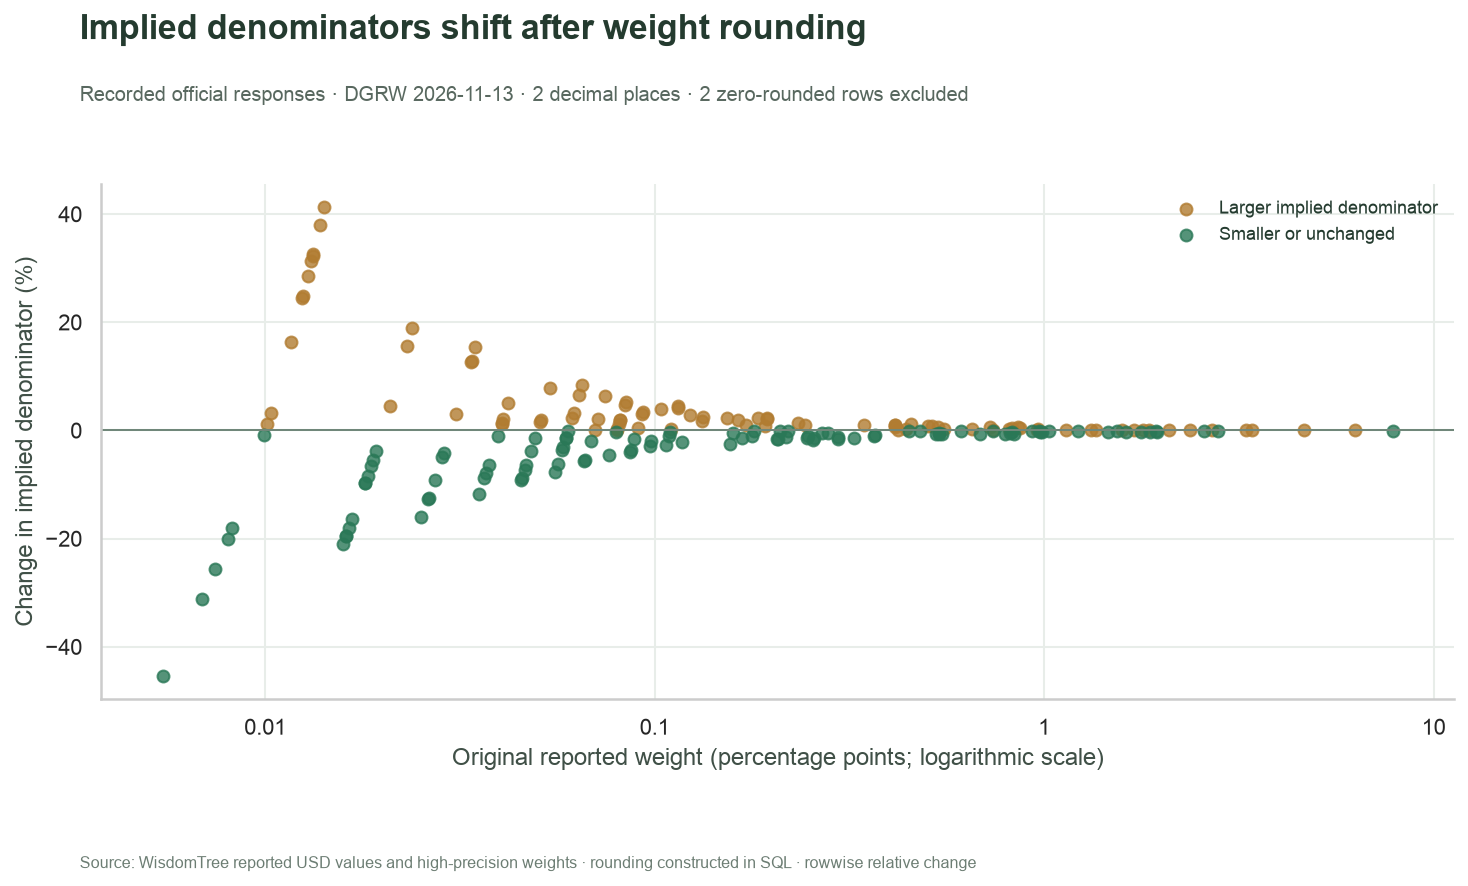

In [11]:
fig, ax = plt.subplots(figsize=(10.5, 6.2))
if len(valid):
    for positive, color, label in [
        (True, "#B17C31", "Larger implied denominator"),
        (False, "#2A7857", "Smaller or unchanged"),
    ]:
        part = valid[(valid.error_percent > 0) == positive]
        ax.scatter(part.weight_percent, part.error_percent, color=color, s=35, alpha=0.8, label=label)
    ax.set_xscale("log")
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _: f"{value:g}"))
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.axhline(0, color="#70877A", linewidth=1)
    ax.legend(loc="upper right", fontsize=9)
else:
    ax.text(0.5, 0.5, "No finite rounded ratios", transform=ax.transAxes, ha="center")
ax.set_xlabel("Original reported weight (percentage points; logarithmic scale)")
ax.set_ylabel("Change in implied denominator (%)")
chart(
    fig,
    "Implied denominators shift after weight rounding",
    f"{mode_label} · DGRW {source_date} · {precision_label} · {zero.rows:.0f} zero-rounded rows excluded",
    "Source: WisdomTree reported USD values and high-precision weights · "
    "rounding constructed in SQL · rowwise relative change",
)

## Compare affected rows with their reported weight

The panels use different units: count on the left, share of original eligible reported weight on the right. Gray identifies undefined ratios from zero-rounded weights. The categories together account for every eligible row and its original weight; they do not redistribute weight among the remaining rows.

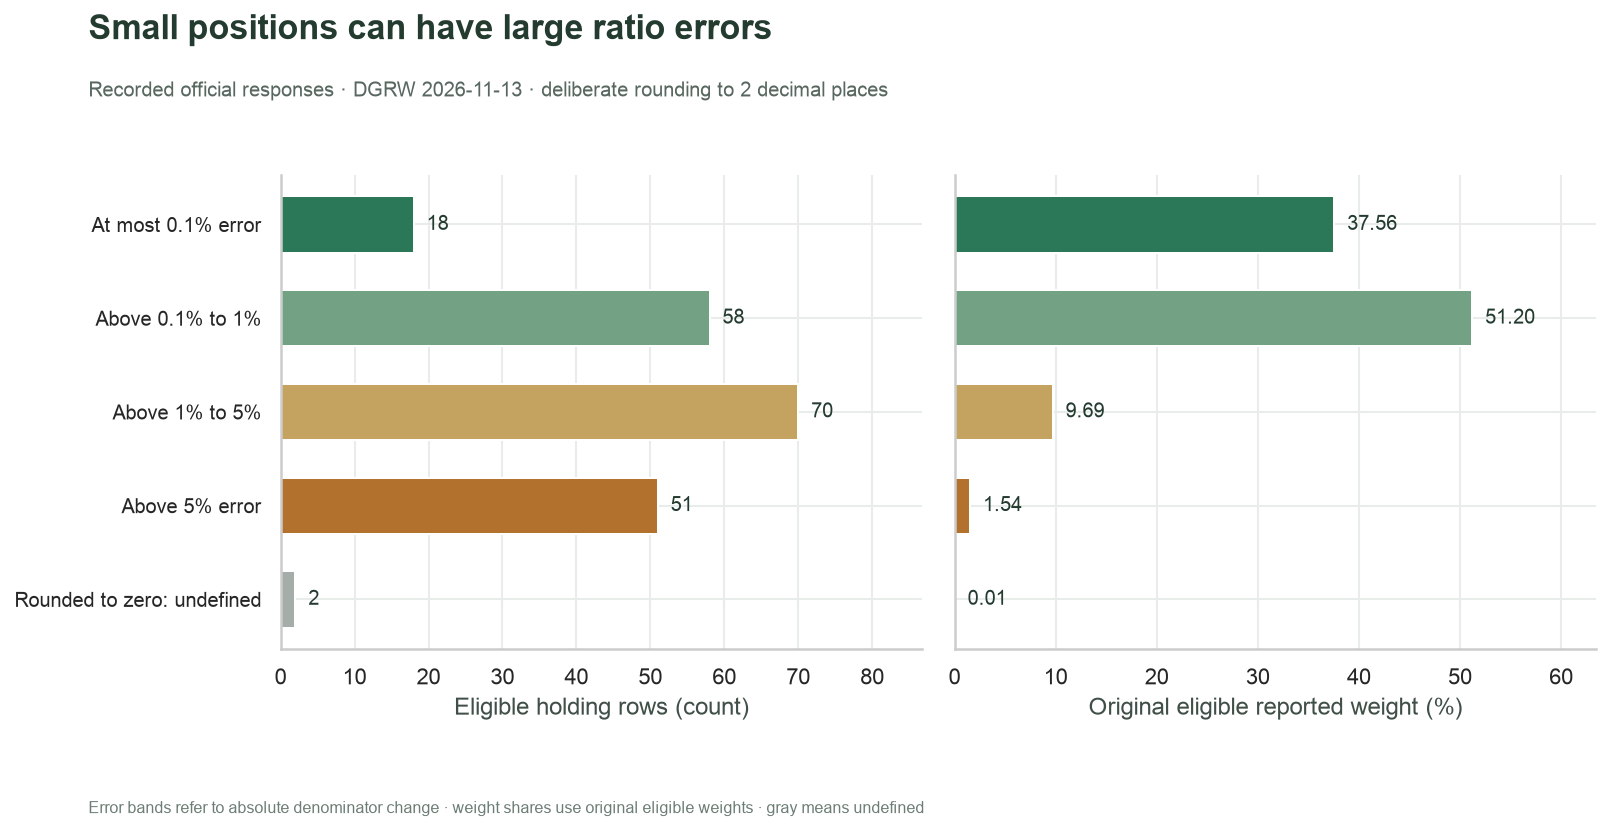

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 5.8), sharey=True)
colors = ["#2A7857", "#72A184", "#C4A25F", "#B2712C", "#A4ADA7"]
y = np.arange(len(bands))
axes[0].barh(y, bands.rows, color=colors, height=0.6)
axes[1].barh(y, bands.eligible_weight_share_percent, color=colors, height=0.6)
axes[0].set_yticks(y, bands.label, fontsize=10)
axes[0].invert_yaxis()
for ax, column, fmt in [(axes[0], "rows", ".0f"), (axes[1], "eligible_weight_share_percent", ".2f")]:
    for pos, value in zip(y, bands[column], strict=True):
        ax.text(
            value + max(1, bands[column].max()) * 0.025, pos, format(value, fmt), va="center", fontsize=10
        )
    ax.set_xlim(0, max(1, bands[column].max()) * 1.24)
axes[0].set_xlabel("Eligible holding rows (count)")
axes[1].set_xlabel("Original eligible reported weight (%)")
chart(
    fig,
    "Small positions can have large ratio errors",
    f"{mode_label} · DGRW {source_date} · deliberate rounding to {precision_label}",
    "Error bands refer to absolute denominator change · weight shares use original eligible weights · "
    "gray means undefined",
)

## Experiment: keep only one decimal place

Change **`WEIGHT_DECIMALS` from 2 to 1**, restart and run all. The increment becomes ten times larger. Predict that the number of positive weights rounded to zero cannot decrease. Compare the undefined count and weight share, signed error scatter and category composition. Measure the error changes rather than assuming they increase identically for every row.

The original rows, market values, reported weights, source date and unrounded ratios must stay fixed in recorded mode. Only the constructed precision changes. Reset `WEIGHT_DECIMALS = 2` afterward; the README saves the experiment separately.

This explains why rounded display weights should not automatically be used to infer accounting totals. It does not establish the issuer’s official denominator or evaluate investment quality. Live mode introduces new source observations and is a separate comparison; missing or unavailable rows never become zero-valued inputs.

In [13]:
connection.close()
cleanup(previous)
plt.close("all")

<a href="https://query.farm/"><img src="assets/query-farm-strata-sun.svg" alt="Query.Farm" width="340"></a>